### 0. Постановка задачи

**Задача:** бинарная классификация компьютерных игр платформы Steam по их характеристикам. Игра считается успешной (класс 1), если доля положительных отзывов составляет не менее 80%, иначе неуспешной (класс 0).

**Цель:** построить модель машинного обучения, способную прогнозировать успешность игры на основе её характеристик.

**Особенности:** исходный датасет содержит 125 855 игр и 40 столбцов После исключения игр без отзывов осталось 82 956 объектов. Данные содержат числовые, категориальные и логические признаки, пропущенные значения и выбросы. Для классификации используется метод k ближайших соседей (kNN).

In [13]:
import csv
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns,matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
DATA_PATH = Path('games.csv')
with DATA_PATH.open(encoding='utf-8-sig', newline='') as f:
    header = next(csv.reader(f))
assert 'DiscountDLC count' in header
position = header.index('DiscountDLC count')
header[position:position+1] = ['Discount', 'DLC count']
df = pd.read_csv(DATA_PATH, header=0, names=header, low_memory=False)
print('Размер:', df.shape)
display(df.head(3))
display(df.dtypes.to_frame('dtype').T)

Размер: (125855, 40)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
dtype,int64,str,str,str,int64,int64,float64,int64,int64,str,...,int64,int64,int64,str,str,str,str,str,str,float64


In [14]:
from sklearn.model_selection import train_test_split

reviews_total = df['Positive'] + df['Negative']
work = df.loc[reviews_total > 0].copy()
work['positive_share'] = work['Positive'] / (work['Positive'] + work['Negative'])
work['target'] = (work['positive_share'] >= .80).astype('int8')
print('Без отзывов исключено:', (reviews_total == 0).sum())
print('Объектов для обучения:', len(work))
print(work['target'].value_counts().sort_index())
print(work['target'].value_counts(normalize=True).sort_index().mul(100).round(2))
train_df, test_df = train_test_split(work, test_size=.20, random_state=42, stratify=work['target'])
print('Train:',train_df.shape,'Test:',test_df.shape)

Без отзывов исключено: 42899
Объектов для обучения: 82956
target
0    37977
1    44979
Name: count, dtype: int64
target
0    45.78
1    54.22
Name: proportion, dtype: float64
Train: (66364, 42) Test: (16592, 42)


,count,mean,std,min,25%,50%,75%,max
AppID,82956.0,1.561580e+06,909540.116997,10.0,800045.000000,1.423605e+06,2.253902e+06,3744990.00
Peak CCU,82956.0,7.801260e+01,4496.734507,0.0,0.000000,0.000000e+00,0.000000e+00,1013936.00
Required age,82956.0,2.196948e-01,1.885554,0.0,0.000000,0.000000e+00,0.000000e+00,21.00
Price,82956.0,5.158420e+00,11.700505,0.0,0.990000,2.990000e+00,5.990000e+00,999.98
Discount,82956.0,2.343956e+01,31.418064,0.0,0.000000,0.000000e+00,5.000000e+01,100.00
DLC count,82956.0,6.958267e-01,17.590449,0.0,0.000000,0.000000e+00,0.000000e+00,3703.00
Metacritic score,82956.0,3.699648e+00,16.267284,0.0,0.000000,0.000000e+00,0.000000e+00,97.00
User score,82956.0,3.628430e-02,1.695715,0.0,0.000000,0.000000e+00,0.000000e+00,100.00
Positive,82956.0,1.544714e+03,34141.024751,0.0,5.000000,1.700000e+01,9.300000e+01,7642084.00
Negative,82956.0,2.501422e+02,6532.646712,0.0,1.000000,5.000000e+00,2.500000e+01,1173003.00


,"Пропуски, %"
Movies,100.000000
Score rank,99.968217
Metacritic url,96.616741
Reviews,90.321402
Notes,81.478686
Website,59.858567
Support url,56.064519
Tags,33.770609
Support email,17.981010
Categories,7.124071


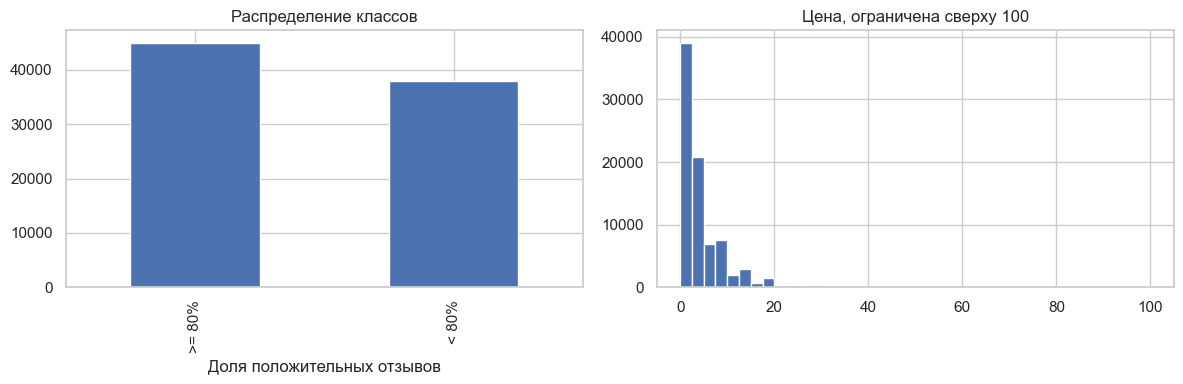

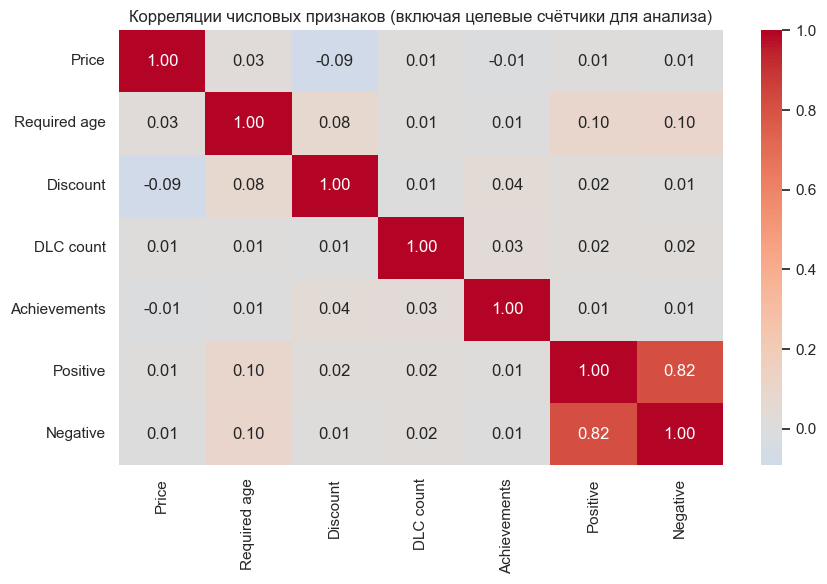

In [15]:
display(work.describe(include='number').T)
missing = df.isna().mean().sort_values(ascending=False).mul(100)
display(missing.to_frame('Пропуски, %').head(20))
fig,ax = plt.subplots(1,2,figsize=(12,4))
work['target'].map({0:'< 80%',1:'>= 80%'}).value_counts().plot.bar(ax=ax[0],title='Распределение классов')
ax[0].set_xlabel('Доля положительных отзывов')
work['Price'].clip(upper=100).hist(bins=40,ax=ax[1]);ax[1].set_title('Цена, ограничена сверху 100')
plt.tight_layout();plt.show()
numerics = ['Price','Required age','Discount','DLC count','Achievements','Positive','Negative']
plt.figure(figsize=(9,6))
sns.heatmap(work[numerics].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0)
plt.title('Корреляции числовых признаков (включая целевые счётчики для анализа)')
plt.tight_layout();plt.show()

**Интерпретация:**

- **Распределение классов:** классы относительно сбалансированы (45,78% и 54,22%).
- **Цена:** большинство игр стоят до 20, распределение смещено вправо, присутствуют дорогие игры-выбросы.
- **Корреляции:** большинство признаков слабо связаны между собой. Наибольшая корреляция между Positive и Negative (0,82).
- **Пропуски:** некоторые столбцы имеют много пропусков, например Movies (100%) и Score rank (99,97%).

In [16]:
for col in ['Price','DLC count','Achievements']:
    x = train_df[col].dropna()
    q1,q3 = x.quantile([.25,.75]); iqr = q3-q1
    cnt = ((x < q1-1.5*iqr)|(x > q3+1.5*iqr)).sum()
    print(f'{col}: IQR={iqr:.2f}; выбросов={cnt} ({cnt/len(x):.1%})')

Price: IQR=5.00; выбросов=4902 (7.4%)
DLC count: IQR=0.00; выбросов=11211 (16.9%)
Achievements: IQR=21.00; выбросов=4174 (6.3%)


**Интерпретация:**

Обнаружены выбросы в цене (7,4%), количестве DLC (16,9%) и достижений (6,3%). Поскольку большие значения могут быть реальными характеристиками игр, выбросы не удаляются. Для уменьшения их влияния используются логарифмирование и RobustScaler.

In [17]:
from collections import Counter
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline

# Выбраны преимущественно предварительные характеристики игры.
num_cols = ['Price','Required age','Discount','DLC count','Achievements']
bool_cols = ['Windows','Mac','Linux']
# Developers/Publishers — высококардинальные признаки: пока исключаем.
# Genres многозначен: ручная бинаризация самых частых жанров.

def collect_genres(s):
    c = Counter()
    for item in s.fillna(''):
        c.update(g.strip() for g in str(item).split(',') if g.strip())
    return [v for v,_ in c.most_common(15)]

popular_genres = collect_genres(train_df['Genres'])
print('Популярные жанры:',popular_genres)

def make_features(source):
    X = source[num_cols + bool_cols].copy()
    for name in popular_genres:
        X['genre: '+name] = source['Genres'].fillna('').apply(
            lambda val: int(name in [g.strip() for g in str(val).split(',')]))
    for name in bool_cols:
        X[name] = X[name].astype(float)
    for name in ['Price','DLC count','Achievements']:
        X[name] = np.log1p(X[name].clip(lower=0))
    return X

X_train = make_features(train_df); X_test = make_features(test_df)
y_train = train_df['target'];y_test = test_df['target']
all_numeric_cols = X_train.columns.tolist()
preprocess = ColumnTransformer([
    ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),
                         ('scaler',RobustScaler())]),all_numeric_cols)
])
print('Признаков модели:',len(all_numeric_cols))
display(X_train.head())

Популярные жанры: ['Indie', 'Action', 'Casual', 'Adventure', 'Simulation', 'Strategy', 'RPG', 'Early Access', 'Free To Play', 'Sports', 'Racing', 'Massively Multiplayer', 'Utilities', 'Design & Illustration', 'Violent']
Признаков модели: 23


,Price,Required age,Discount,DLC count,Achievements,Windows,Mac,Linux,genre: Indie,genre: Action,...,genre: Strategy,genre: RPG,genre: Early Access,genre: Free To Play,genre: Sports,genre: Racing,genre: Massively Multiplayer,genre: Utilities,genre: Design & Illustration,genre: Violent
62769,0.398776,0,51,0.000000,1.098612,1.0,0.0,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
2826,2.771964,0,0,0.000000,2.833213,1.0,0.0,0.0,0,1,...,0,0,1,0,0,0,0,0,0,0
99273,2.196113,0,0,0.000000,0.000000,1.0,0.0,0.0,1,0,...,1,1,0,0,0,0,0,0,0,0
72776,2.396986,0,0,0.000000,0.000000,1.0,0.0,0.0,0,0,...,0,1,0,0,0,0,0,0,0,0
49269,1.790091,0,0,0.693147,3.713572,1.0,0.0,0.0,1,0,...,0,1,0,0,0,0,0,0,0,0


,k,val_accuracy,val_f1
0,3,0.5676,0.613653
1,5,0.5792,0.625889
2,9,0.5822,0.636506
3,15,0.5910,0.652033
4,25,0.5916,0.657727
5,41,0.5942,0.669813


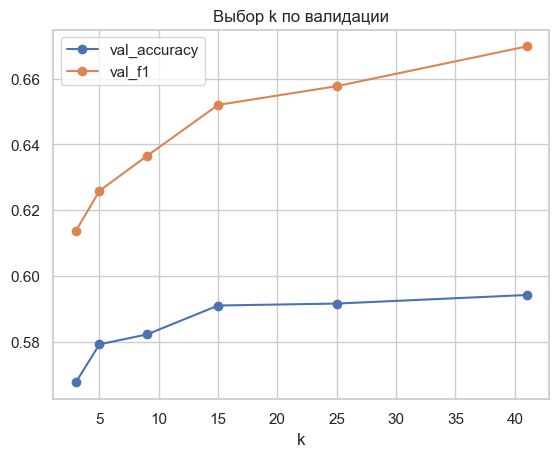

Оптимальное k по F1: 41


In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedShuffleSplit

N_TUNE = min(20000, len(X_train))
idx_all = np.arange(len(X_train))
idx_tune, _ = train_test_split(idx_all, train_size=N_TUNE,
                              random_state=42,stratify=y_train)
Xt = X_train.iloc[idx_tune]; yt = y_train.iloc[idx_tune]
ix_fit,ix_val = train_test_split(np.arange(len(Xt)),test_size=.25,
                                 random_state=42,stratify=yt)
results=[]
for k in [3,5,9,15,25,41]:
    pipe = Pipeline([('preprocess',preprocess),('classifier',KNeighborsClassifier(n_neighbors=k,n_jobs=-1))])
    pipe.fit(Xt.iloc[ix_fit],yt.iloc[ix_fit])
    pred=pipe.predict(Xt.iloc[ix_val])
    results.append({'k':k,'val_accuracy':accuracy_score(yt.iloc[ix_val],pred),
                    'val_f1':f1_score(yt.iloc[ix_val],pred)})
res=pd.DataFrame(results)
display(res)
res.plot(x='k',y=['val_accuracy','val_f1'],marker='o',title='Выбор k по валидации')
plt.show()
best_k=int(res.sort_values('val_f1',ascending=False).iloc[0]['k'])
print('Оптимальное k по F1:',best_k)

**Обоснование выбора метода:**

Выбран метод k ближайших соседей (kNN), поскольку он подходит для бинарной классификации, прост в реализации и не предполагает линейной зависимости между признаками и целевой переменной. Перед обучением признаки масштабируются, поскольку алгоритм основан на вычислении расстояний между объектами.

Train: Accuracy=0.6223, F1=0.6840
              precision    recall  f1-score   support

           0       0.62      0.47      0.53      9156
           1       0.63      0.75      0.68     10844

    accuracy                           0.62     20000
   macro avg       0.62      0.61      0.61     20000
weighted avg       0.62      0.62      0.61     20000



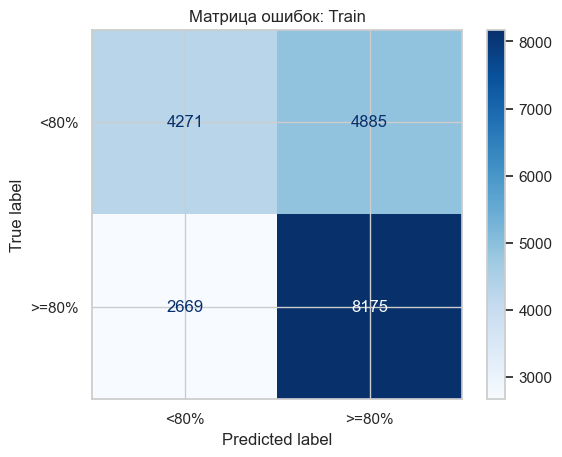

Test: Accuracy=0.6014, F1=0.6663
              precision    recall  f1-score   support

           0       0.59      0.44      0.51      2289
           1       0.61      0.73      0.67      2711

    accuracy                           0.60      5000
   macro avg       0.60      0.59      0.59      5000
weighted avg       0.60      0.60      0.59      5000



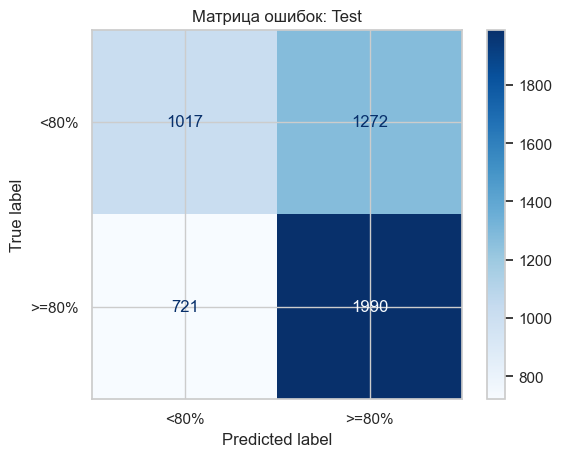

In [19]:
# Финальная подгонка на всей подвыборке и оценка на отложенном тесте.
model=Pipeline([('preprocess',preprocess),
                ('classifier',KNeighborsClassifier(n_neighbors=best_k,n_jobs=-1))])
model.fit(Xt,yt)
train_pred=model.predict(Xt)
# Для скорости тестируем максимум 5000 объектов, случайно и стратифицированно.
if len(X_test)>5000:
    itest,_=train_test_split(np.arange(len(X_test)),train_size=5000,
                             random_state=42,stratify=y_test)
else: itest=np.arange(len(X_test))
ypred=model.predict(X_test.iloc[itest])
for label,actual,pred in [('Train',yt,train_pred),('Test',y_test.iloc[itest],ypred)]:
    print(f'{label}: Accuracy={accuracy_score(actual,pred):.4f}, F1={f1_score(actual,pred):.4f}')
    print(classification_report(actual,pred,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(actual,pred,display_labels=['<80%','>=80%'],cmap='Blues')
    plt.title(f'Матрица ошибок: {label}');plt.show()

**Интерпретация:**

На тестовой выборке Accuracy = 60,14%, F1 = 66,63%. Модель правильно классифицировала 3007 из 5000 игр. Успешные игры распознаются лучше неуспешных (полнота 0,73 против 0,44). Существенного переобучения не наблюдается, однако качество прогнозирования остаётся невысоким.

### 13. Общие выводы

1) В ходе работы была построена модель бинарной классификации для прогнозирования успешности компьютерных игр платформы Steam.

2) После удаления 42 899 игр без отзывов осталось 82 956 объектов. Распределение классов составило 45,78% неуспешных и 54,22% успешных игр.

3) При анализе данных обнаружены пропущенные значения и выбросы. Например, выбросы составили 7,4% для цены, 16,9% для количества DLC и 6,3% для количества достижений. Пропуски числовых признаков обрабатывались заполнением медианой, а для уменьшения влияния выбросов применялись логарифмическое преобразование и масштабирование.

4) Для обучения модели использовалось 23 признака. Методом перебора значений количества соседей наилучшее среди рассмотренных значение **k = 41** было выбрано по метрике F1.

5) На обучающей подвыборке получены Accuracy = 0,6223 и F1 = 0,6840, на тестовой подвыборке - Accuracy = 0,6014 и F1 = 0,6663.

6) Разница между качеством на обучающих и тестовых данных небольшая, что не указывает на выраженное переобучение. Однако общая точность классификации остаётся умеренной.

Таким образом, модель kNN позволяет выявлять некоторую зависимость между характеристиками игр и их пользовательскими оценками, но её предсказательная способность пока ограничена. Для улучшения результатов можно использовать дополнительные признаки и более сложные алгоритмы классификации.